# Netflix Content Recommendation System
## Exploratory Data Analysis & End-to-End Pipeline Walkthrough

This notebook presents an end-to-end exploration of the Netflix catalog, feature engineering pipeline, recommendation generation, and quantitative RecSys evaluation.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add src to path
sys.path.append('..')
from src.data_preprocessing import load_and_preprocess_data
from src.feature_engineering import build_metadata_soup, TextVectorizer
from src.recommendation_engine import NetflixRecommender
from src.evaluation import RecommendationEvaluator

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'

### 1. Data Ingestion & Overview

In [2]:
df = load_and_preprocess_data('../data/Dataset.csv')
print(f"Catalog size: {df.shape[0]} titles, {df.shape[1]} columns")
df.head(3)

Catalog size: 8786 titles, 10 columns


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"


### 2. Exploratory Visualizations: Catalog Composition & Timeline

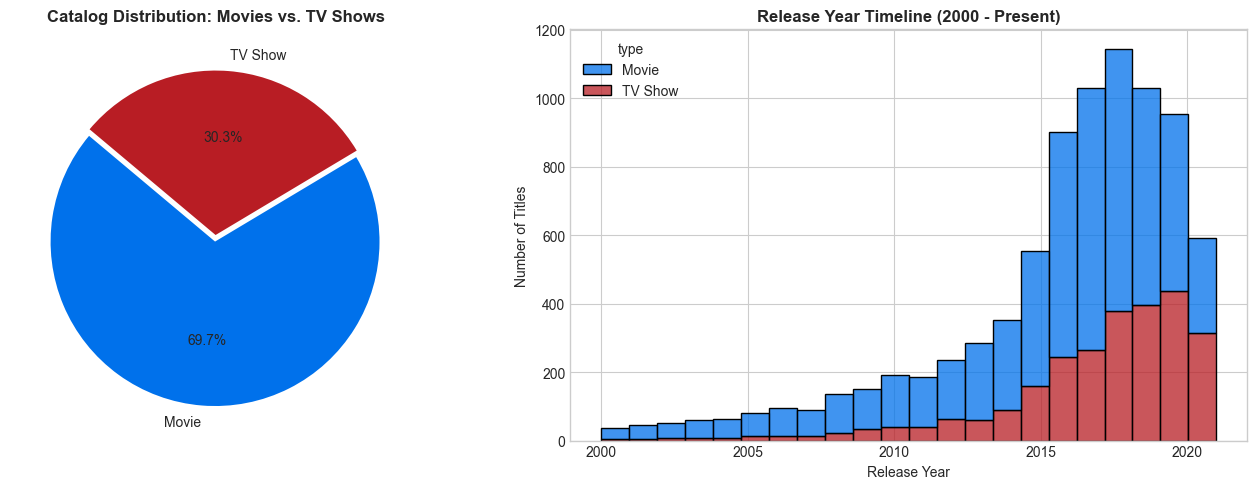

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Format split
type_counts = df['type'].value_counts()
axes[0].pie(type_counts, labels=type_counts.index, autopct='%1.1f%%',
            colors=['#0071eb', '#b81d24'], startangle=140, explode=(0.04, 0))
axes[0].set_title('Catalog Distribution: Movies vs. TV Shows', fontweight='bold')

# Release year trend (post-2000)
recent_df = df[df['release_year'] >= 2000]
sns.histplot(data=recent_df, x='release_year', hue='type', multiple='stack',
             palette=['#0071eb', '#b81d24'], bins=22, ax=axes[1])
axes[1].set_title('Release Year Timeline (2000 - Present)', fontweight='bold')
axes[1].set_xlabel('Release Year')
axes[1].set_ylabel('Number of Titles')

plt.tight_layout()
plt.show()

### 3. Initialize & Fit Recommender Engine

In [4]:
recommender = NetflixRecommender(genre_weight=2)
recommender.fit(df)
print(f"TF-IDF Feature Space Dimensions: {recommender.tfidf_matrix.shape}")

TF-IDF Feature Space Dimensions: (8786, 1148)


### 4. Recommendation Queries & Results

In [5]:
# Query 1: Stranger Things
recs_st = recommender.recommend('Stranger Things', top_k=5)
print("Recommendations for 'Stranger Things':")
recs_st[['title', 'type', 'release_year', 'rating', 'similarity_score', 'listed_in']]

Recommendations for 'Stranger Things':


,title,type,release_year,rating,similarity_score,listed_in
0,Chilling Adventures of Sabrina,TV Show,2020,TV-14,1.0000,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy"
1,Helix,TV Show,2015,TV-MA,0.9831,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy"
2,Nightflyers,TV Show,2018,TV-MA,0.9831,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy"
3,The Mystic River,TV Show,2020,TV-14,0.7860,"International TV Shows, TV Horror, TV Sci-Fi &..."
4,The Originals,TV Show,2018,TV-14,0.7658,"TV Dramas, TV Horror, TV Mysteries"


In [6]:
# Query 2: Narcos (Filtered to TV Shows only)
recs_narcos = recommender.recommend('Narcos', top_k=5, filter_type='TV Show')
print("Recommendations for 'Narcos':")
recs_narcos[['title', 'type', 'release_year', 'rating', 'similarity_score', 'listed_in']]

Recommendations for 'Narcos':


,title,type,release_year,rating,similarity_score,listed_in
0,Marvel's The Defenders,TV Show,2017,TV-MA,1.0,"Crime TV Shows, TV Action & Adventure, TV Dramas"
1,Altered Carbon,TV Show,2020,TV-MA,1.0,"Crime TV Shows, TV Action & Adventure, TV Dramas"
2,Marvel's Luke Cage,TV Show,2018,TV-MA,1.0,"Crime TV Shows, TV Action & Adventure, TV Dramas"
3,Marvel's Jessica Jones,TV Show,2019,TV-MA,1.0,"Crime TV Shows, TV Action & Adventure, TV Dramas"
4,Queen of the South,TV Show,2018,TV-MA,1.0,"Crime TV Shows, TV Action & Adventure, TV Dramas"


### 5. Quantitative RecSys Evaluation
We evaluate Precision@5, Catalog Coverage, and Intra-List Diversity across a random sample of catalog titles.

In [7]:
evaluator = RecommendationEvaluator(recommender)
results = evaluator.evaluate_catalog(sample_size=100, k=5)

for metric, val in results.items():
    print(f"{metric:<26}: {val}")

sample_size               : 100
k                         : 5
mean_precision_at_k       : 0.992
mean_recall_at_k          : 0.0047
mean_f1_at_k              : 0.0091
catalog_coverage_pct      : 5.24
mean_intra_list_diversity : 0.1334
